# 12장 사후 실험. 검증 데이터 다시 설계하기

「AI로 만드는 제조공정 품질관리 따라하기」 12-4 사후 실험 Notebook입니다.
12장 본 실험은 검증 데이터(Training 뒤쪽 Lot 20%)에 결함 맵이 110장뿐이라 모델 선택이 우연에 좌우되었습니다.
12-4 끝에 적은 개선안을 그대로 실행해, 검증 설계를 바꾸면 선택과 결과가 어떻게 달라지는지 확인합니다.

사후 실험이라는 점: 12장 평가 결과를 이미 본 뒤에 하는 실험입니다. 그래서 규칙을 아래처럼 먼저 고정하고,
이 실험의 결과로 12장 본문의 최종 모델을 바꾸지 않습니다.

실험 설계(이 Notebook을 실행하기 전에 정함)
- 분리 A(12장과 같음): Training 뒤쪽 Lot 20%를 검증. 설정별 시드 42·43·44. 선택 = 검증 macro F1 평균 최대, 최종 = 선택 설정의 시드 3개 앙상블
- 분리 B(새 설계): Training을 Lot 단위로 유형 비율을 맞춰 5겹으로 나눔(StratifiedGroupKFold, shuffle, 시드 42).
  설정별로 겹마다 한 번(시드 42) 학습. 선택 = 5겹 검증 macro F1 평균 최대, 최종 = 선택 설정의 5겹 모델 앙상블
- 두 분리 모두 설정 4개(SmallCNN, SmallCNN 클래스 가중치, ResNet18 사전학습, ResNet18 무작위 초기화)와 학습 방법은 12장과 같음.
  ResNet의 클래스 가중치 사용 여부도 12장 규칙(SmallCNN 두 설정의 검증 평균 비교)을 분리마다 따로 적용
- 평가: 공식 Test 118,595장. 시간 방향(나중 Lot)은 평가 데이터가 맡음
- 비교할 것: 검증 데이터의 유형별 장수, 검증 순위와 평가 순위의 일치(4개 설정의 Spearman 상관), 선택된 설정과 최종 평가 macro F1
- 측정 장비가 12장(GTX 1080)과 다르므로, 분리 A도 같은 장비에서 다시 돌려 같은 장비 안에서 비교함

In [1]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    !git clone -q https://github.com/ady95/manufacturing-ai-tutorial.git
    %cd manufacturing-ai-tutorial/03-defect-inspection/wafermap
    !pip install -q -U kaggle
    from google.colab import userdata
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
Path("results").mkdir(exist_ok=True)

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import spearmanr
from sklearn.model_selection import StratifiedGroupKFold

from src.cnn_train import SmallCNN, class_weight, make_resnet, predict, train_model
from src.wafer_utils import CLASSES, SEED, classification_report_dict, dev_val_split, env_info, prepare

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.benchmark = True
ENV = env_info()
print(ENV, "| 장치", DEVICE)

{'python': '3.12.15', 'numpy': '2.5.5', 'pandas': '3.1.1', 'sklearn': '1.9.1', 'opencv': '5.1.0', 'torch': '2.14.1+cu126', 'torchvision': '0.29.1+cu126', 'device': 'NVIDIA GeForce RTX 3090'} | 장치 cuda


## 데이터와 두 가지 검증 분리

In [3]:
D = prepare()
y_all = D["y"]
is_train, is_test = D["split"] == "Training", D["split"] == "Test"
none_i = CLASSES.index("none")

# 분리 A: 12장과 같음
tr_a, va_a = dev_val_split(D["lot_num"], is_train)
SPLIT_A = [(tr_a, va_a)]

# 분리 B: Lot 단위 + 유형 비율 유지 5겹
train_idx = np.flatnonzero(is_train)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
SPLIT_B = []
for k_tr, k_va in sgkf.split(train_idx, y_all[train_idx], groups=D["lot"][train_idx]):
    tr = np.zeros(len(y_all), bool); va = np.zeros(len(y_all), bool)
    tr[train_idx[k_tr]] = True; va[train_idx[k_va]] = True
    SPLIT_B.append((tr, va))


def val_counts(splits):
    rows = []
    for k, (tr, va) in enumerate(splits):
        c = np.bincount(y_all[va], minlength=len(CLASSES))
        rows.append({"fold": k, "train": int(tr.sum()), "val": int(va.sum()), "val_defect": int(va.sum() - c[none_i]),
                     **dict(zip(CLASSES, c.tolist()))})
    return pd.DataFrame(rows)


counts_a, counts_b = val_counts(SPLIT_A), val_counts(SPLIT_B)
print("분리 A 검증 유형별 장수\n", counts_a.to_string(index=False))
print("분리 B 검증 유형별 장수(겹별)\n", counts_b.to_string(index=False))
for tr, va in SPLIT_B:                                             # 같은 Lot이 학습·검증에 동시에 들어가지 않았는지 확인
    assert not set(D["lot"][tr]) & set(D["lot"][va])

maps_gpu = torch.from_numpy(D["maps"]).to(DEVICE)
y_gpu = torch.from_numpy(y_all).to(DEVICE)
idx_te = torch.from_numpy(np.flatnonzero(is_test)).to(DEVICE)
yt = y_all[is_test]

분리 A 검증 유형별 장수
  fold  train   val  val_defect  Center  Donut  Edge-Loc  Edge-Ring  Loc  Near-full  Random  Scratch  none
    0  43461 10894         110       8      1        41          9   32          8       4        7 10784
분리 B 검증 유형별 장수(겹별)
  fold  train   val  val_defect  Center  Donut  Edge-Loc  Edge-Ring  Loc  Near-full  Random  Scratch  none
    0  43486 10869        3525     693     82       483       1711  324         10     122      100  7344
    1  43474 10881        3522     692     81       483       1710  324         11     121      100  7359
    2  43486 10869        3527     693     82       484       1711  324         11     122      100  7342
    3  43487 10868        3526     692     82       484       1711  324         11     122      100  7342
    4  43487 10868        3525     692     82       483       1711  324         11     122      100  7343


## 학습

In [4]:
CACHE = Path("results/12b_runs")
CACHE.mkdir(exist_ok=True)


def run(split_name, k, tr, va, cfg_name, make, use_cw, seed):
    """학습 1회. 끝난 학습은 결과를 저장해 두고 다시 실행하면 불러온다."""
    slug = f"{split_name}_fold{k}_{cfg_name}_seed{seed}".replace(" ", "_").replace("(", "").replace(")", "")
    f_json, f_npy = CACHE / f"{slug}.json", CACHE / f"{slug}.npy"
    if f_json.exists() and f_npy.exists():
        return json.loads(f_json.read_text(encoding="utf-8")), np.load(f_npy)
    idx_tr = torch.from_numpy(np.flatnonzero(tr)).to(DEVICE)
    idx_va = torch.from_numpy(np.flatnonzero(va)).to(DEVICE)
    cw = class_weight(y_all[tr], DEVICE) if use_cw else None
    model, hist, sec, best = train_model(make, seed, maps_gpu, y_gpu, y_all, idx_tr, idx_va, class_weight=cw)
    proba = predict(model, maps_gpu, idx_te).cpu().numpy().astype(np.float32)
    vals = [h["val_macro_f1"] for h in hist]
    r = {"split": split_name, "fold": k, "config": cfg_name, "seed": seed, "class_weight": bool(use_cw),
         "epochs": len(hist), "best_epoch": int(np.argmax(vals) + 1), "train_sec": round(sec, 1),
         "val_macro_f1": best, "max_epoch_jump": round(float(np.max(np.abs(np.diff(vals)))) if len(vals) > 1 else 0.0, 4),
         "test_macro_f1": classification_report_dict(yt, proba.argmax(1))["macro_f1"], "hist": hist}
    f_json.write_text(json.dumps(r, ensure_ascii=False), encoding="utf-8")
    np.save(f_npy, proba)
    del model
    torch.cuda.empty_cache()
    return r, proba


def run_split(split_name, splits, seeds):
    """12장 순서 그대로: SmallCNN 두 설정 → 검증 평균으로 ResNet의 클래스 가중치 결정 → ResNet 두 설정."""
    runs, probas = {}, {}

    def do(cfg_name, make, use_cw):
        runs[cfg_name], probas[cfg_name] = [], []
        for k, (tr, va) in enumerate(splits):
            for seed in seeds:
                r, p = run(split_name, k, tr, va, cfg_name, make, use_cw, seed)
                runs[cfg_name].append(r); probas[cfg_name].append(p)
                print(f"[{split_name}] {cfg_name} fold{k} seed{seed}: epoch {r['epochs']:2d}(최고 {r['best_epoch']}) "
                      f"| {r['train_sec']:6.1f}초 | 검증 {r['val_macro_f1']:.3f} | 평가 {r['test_macro_f1']:.3f}", flush=True)

    do("CNN", SmallCNN, False)
    do("CNN (클래스 가중치)", SmallCNN, True)
    vm = {k: np.mean([r["val_macro_f1"] for r in v]) for k, v in runs.items()}
    use_w = bool(vm["CNN (클래스 가중치)"] > vm["CNN"])
    print(f"[{split_name}] ResNet 클래스 가중치 사용: {use_w}")
    do("ResNet18 (사전학습)", lambda: make_resnet(True), use_w)
    do("ResNet18 (무작위 초기화)", lambda: make_resnet(False), use_w)
    return runs, probas, use_w


runs_a, probas_a, w_a = run_split("A", SPLIT_A, seeds=(42, 43, 44))
runs_b, probas_b, w_b = run_split("B", SPLIT_B, seeds=(42,))

[A] CNN fold0 seed42: epoch 17(최고 11) |   87.8초 | 검증 0.821 | 평가 0.630


[A] CNN fold0 seed43: epoch 20(최고 14) |   90.8초 | 검증 0.793 | 평가 0.658


[A] CNN fold0 seed44: epoch 21(최고 15) |   95.2초 | 검증 0.838 | 평가 0.666


[A] CNN (클래스 가중치) fold0 seed42: epoch 17(최고 11) |   77.1초 | 검증 0.786 | 평가 0.642


[A] CNN (클래스 가중치) fold0 seed43: epoch 11(최고 5) |   49.9초 | 검증 0.752 | 평가 0.609


[A] CNN (클래스 가중치) fold0 seed44: epoch 12(최고 6) |   54.5초 | 검증 0.817 | 평가 0.611


... (24 outputs left out)

[B] ResNet18 (무작위 초기화) fold1 seed42: epoch 13(최고 7) |   62.5초 | 검증 0.926 | 평가 0.675


[B] ResNet18 (무작위 초기화) fold2 seed42: epoch 30(최고 24) |  144.8초 | 검증 0.943 | 평가 0.714


[B] ResNet18 (무작위 초기화) fold3 seed42: epoch 30(최고 25) |  145.6초 | 검증 0.938 | 평가 0.711


[B] ResNet18 (무작위 초기화) fold4 seed42: epoch 22(최고 16) |  109.1초 | 검증 0.928 | 평가 0.705


## 결과 비교

In [5]:
def summarize(name, runs, probas):
    rows = []
    for cfg, rs in runs.items():
        rows.append({"split": name, "config": cfg,
                     "val_mean": np.mean([r["val_macro_f1"] for r in rs]),
                     "val_sd": np.std([r["val_macro_f1"] for r in rs]),
                     "test_mean": np.mean([r["test_macro_f1"] for r in rs]),
                     "test_sd": np.std([r["test_macro_f1"] for r in rs]),
                     "max_epoch_jump_mean": np.mean([r["max_epoch_jump"] for r in rs]),
                     "train_sec_mean": np.mean([r["train_sec"] for r in rs])})
    t = pd.DataFrame(rows)
    rho = spearmanr(t["val_mean"], t["test_mean"]).statistic
    chosen = t.loc[t["val_mean"].idxmax(), "config"]
    ens = np.mean(probas[chosen], axis=0).argmax(1)
    rep = classification_report_dict(yt, ens)
    missed = int(((yt != none_i) & (ens == none_i)).sum())
    return t, {"spearman_val_test": float(rho), "chosen": chosen, "n_models_in_ensemble": len(probas[chosen]),
               "ensemble_test_macro_f1": rep["macro_f1"], "ensemble_test_accuracy": rep["accuracy"],
               "missed_defects": missed, "n_test_defects": int((yt != none_i).sum()),
               "per_class_f1": {c: v["f1"] for c, v in rep["per_class"].items()}}


tab_a, sum_a = summarize("A", runs_a, probas_a)
tab_b, sum_b = summarize("B", runs_b, probas_b)
table = pd.concat([tab_a, tab_b]).round(4)
print(table.to_string(index=False))
print("분리 A:", {k: v for k, v in sum_a.items() if k != "per_class_f1"})
print("분리 B:", {k: v for k, v in sum_b.items() if k != "per_class_f1"})

split             config  val_mean  val_sd  test_mean  test_sd  max_epoch_jump_mean  train_sec_mean
    A                CNN    0.8172  0.0186     0.6516   0.0153               0.2932         91.2667
    A      CNN (클래스 가중치)    0.7852  0.0266     0.6207   0.0152               0.2154         60.5000
    A    ResNet18 (사전학습)    0.8089  0.0441     0.6865   0.0222               0.1315         67.7333
    A ResNet18 (무작위 초기화)    0.8675  0.0162     0.6849   0.0146               0.2165         64.3333
    B                CNN    0.9157  0.0080     0.6477   0.0166               0.1822        105.1600
    B      CNN (클래스 가중치)    0.9150  0.0160     0.6542   0.0330               0.2029         99.7000
    B    ResNet18 (사전학습)    0.9419  0.0082     0.6895   0.0190               0.0691        105.6400
    B ResNet18 (무작위 초기화)    0.9299  0.0101     0.6986   0.0149               0.0983        109.2800
분리 A: {'spearman_val_test': 0.39999999999999997, 'chosen': 'ResNet18 (무작위 초기화)', 'n_models_in_ensemb

In [6]:
# 겹마다 따로 고른다면 선택이 얼마나 흔들렸을지: 겹 하나의 검증만 보고 고른 설정
per_fold_choice = []
for k in range(len(SPLIT_B)):
    v = {cfg: [r for r in rs if r["fold"] == k][0]["val_macro_f1"] for cfg, rs in runs_b.items()}
    per_fold_choice.append(max(v, key=v.get))
print("겹 하나만 보고 고른 설정:", per_fold_choice)

겹 하나만 보고 고른 설정: ['ResNet18 (사전학습)', 'ResNet18 (사전학습)', 'ResNet18 (사전학습)', 'ResNet18 (사전학습)', 'ResNet18 (사전학습)']


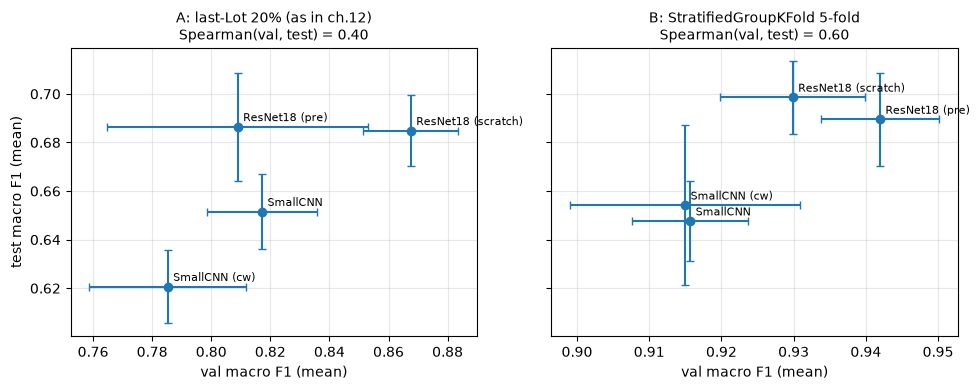

In [7]:
EN = {"CNN": "SmallCNN", "CNN (클래스 가중치)": "SmallCNN (cw)", "ResNet18 (사전학습)": "ResNet18 (pre)",
      "ResNet18 (무작위 초기화)": "ResNet18 (scratch)"}
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (name, t, s) in zip(axes, [("A: last-Lot 20% (as in ch.12)", tab_a, sum_a),
                                   ("B: StratifiedGroupKFold 5-fold", tab_b, sum_b)]):
    ax.errorbar(t["val_mean"], t["test_mean"], xerr=t["val_sd"], yerr=t["test_sd"], fmt="o", capsize=3)
    for _, row in t.iterrows():
        ax.annotate(EN[row["config"]], (row["val_mean"], row["test_mean"]), fontsize=8,
                    xytext=(4, 4), textcoords="offset points")
    ax.set_title(f"{name}\nSpearman(val, test) = {s['spearman_val_test']:.2f}", fontsize=10)
    ax.set_xlabel("val macro F1 (mean)"); ax.grid(alpha=0.3)
axes[0].set_ylabel("test macro F1 (mean)")
plt.tight_layout()
plt.savefig("results/12b_val_vs_test.png", dpi=110)
plt.show()

In [8]:
out = {
    "env": ENV, "device": DEVICE,
    "design": {"A": "Training 뒤쪽 Lot 20%, 시드 42·43·44", "B": "StratifiedGroupKFold 5겹(Lot 단위, 시드 42), 겹마다 시드 42"},
    "val_counts": {"A": counts_a.to_dict("records"), "B": counts_b.to_dict("records")},
    "resnet_uses_class_weight": {"A": w_a, "B": w_b},
    "table": table.to_dict("records"),
    "summary": {"A": sum_a, "B": sum_b},
    "per_fold_choice_B": per_fold_choice,
    "runs": {"A": {k: [{kk: vv for kk, vv in r.items() if kk != "hist"} for r in v] for k, v in runs_a.items()},
             "B": {k: [{kk: vv for kk, vv in r.items() if kk != "hist"} for r in v] for k, v in runs_b.items()}},
}
Path("results/12b_validation.json").write_text(json.dumps(out, ensure_ascii=False, indent=2, default=float), encoding="utf-8")

16771